# Machine Learning Classification Project: Diabetes Prediction

## Introduction

Classification is a supervised machine learning technique in which a model learns from labeled data to categorize observations into predefined classes. It is widely used in healthcare diagnostics, fraud detection, and predictive analytics. In this project, I build and compare binary classification models to predict whether a patient has diabetes based on diagnostic health measurements.

## Project Workflow

Before diving into implementation, I establish a structured machine learning pipeline tailored to my actual workflow—from data loading and preprocessing to model comparison and inference.

### 1. **Define the Problem**

Frame the task as a binary classification problem. Using diagnostic medical metrics (such as `Glucose`, `BMI`, `Age`, `Insulin`, and `BloodPressure`), the objective is to predict whether a patient is diabetic (`Outcome = 1`) or non-diabetic (`Outcome = 0`).

### 2. **Collect & Understand the Data**

Load the Pima Indians Diabetes dataset (`diabetes.csv`) and conduct Exploratory Data Analysis (EDA) using summary statistics (`.head()`, `.tail()`, `.describe()`, `.info()`) and visualizations to inspect feature distributions, detect invalid zero values, and examine correlations with the target variable.

### 3. **Preprocess the Data**

Prepare the dataset for modeling by separating features (`X`) from the target (`y`), splitting the data into stratified training (80%) and testing (20%) sets (`train_test_split`), and applying feature standardization (`StandardScaler`) where required for distance- and gradient-based algorithms.

### 4. **Feature Analysis & Importance**

Examine feature relationships via correlation matrices and evaluate post-training feature importances (from tree-based models) to identify which clinical indicators contribute most strongly to diabetes predictions.

### 5. **Choose & Train the Models**

Train and experiment with multiple classification algorithms on the training set to compare linear and tree-based approaches:
* **Logistic Regression** (baseline linear classifier)
* **Decision Tree Classifier** (non-linear rule-based model)
* **Random Forest Classifier** (ensemble of decision trees for improved generalization)

### 6. **Evaluate & Compare the Models**

Assess model performance on the unseen test set using **Accuracy**, **Precision**, **Recall**, **F1 Score**, and **Confusion Matrices**, then build a single-instance predictive system to test real-world patient inference.

---

With this roadmap established, I now proceed to implement each stage step-by-step in Python.

# 1. Loading & Understanding the Data

## PIMA Diabetes Dataset

In [7]:
import pandas as pd

In [8]:
diabetes_dataset = pd.read_csv('diabetes.csv')

In [9]:
diabetes_dataset.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# print the last 5 rows of the dataset using `.tail()`

In [10]:
diabetes_dataset.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [11]:
# number of rows and Columns in this dataset
diabetes_dataset.shape

(768, 9)

In [12]:
# getting the statistical measures of the data
diabetes_dataset.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


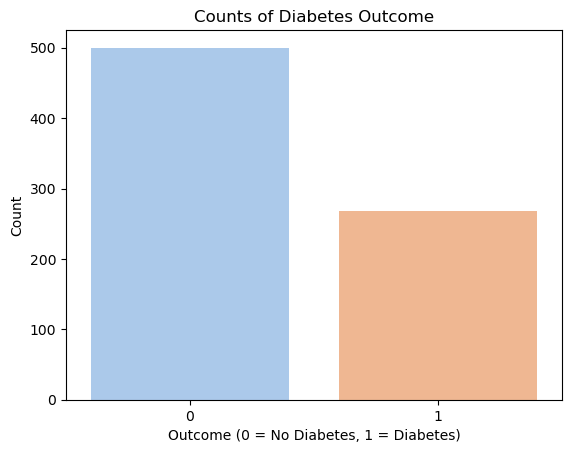

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='Outcome', data=diabetes_dataset, palette='pastel') #other palette muted,bright,deep,colorblind,dark

# Add title and labels
plt.title('Counts of Diabetes Outcome')
plt.xlabel('Outcome (0 = No Diabetes, 1 = Diabetes)')
plt.ylabel('Count')

plt.show()

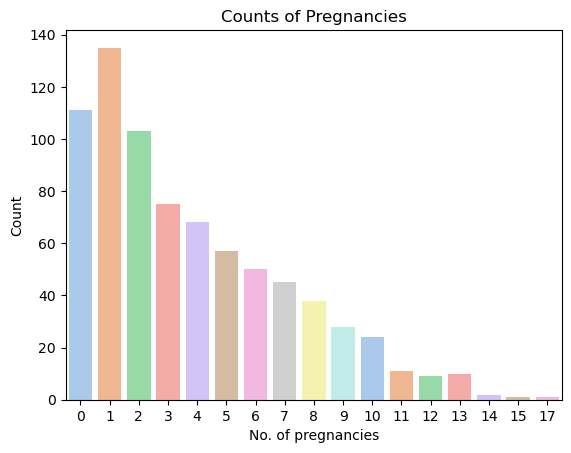

In [14]:


sns.countplot(x='Pregnancies', data=diabetes_dataset, palette='pastel')

plt.title('Counts of Pregnancies')
plt.xlabel('No. of pregnancies')
plt.ylabel('Count')

plt.show()


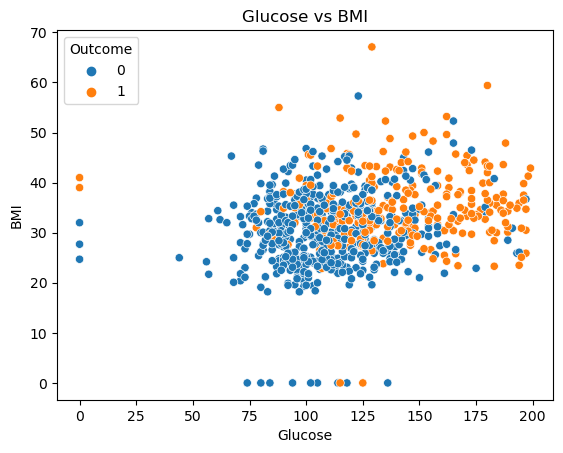

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns


feature1 = 'Glucose'
feature2 = 'BMI'

sns.scatterplot(x=feature1, y=feature2, data=diabetes_dataset, hue='Outcome')
plt.title('Glucose vs BMI')
plt.xlabel(feature1)
plt.ylabel(feature2)
plt.show()

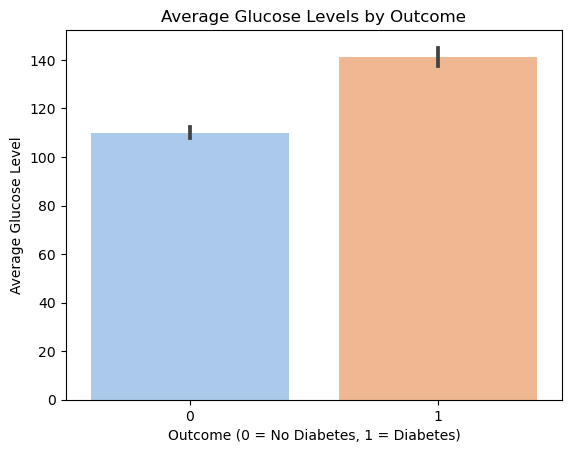

In [16]:
sns.barplot(x='Outcome', y='Glucose', data=diabetes_dataset, estimator='mean', palette='pastel')

# Add title and labels
plt.title('Average Glucose Levels by Outcome')
plt.xlabel('Outcome (0 = No Diabetes, 1 = Diabetes)')
plt.ylabel('Average Glucose Level')

plt.show()

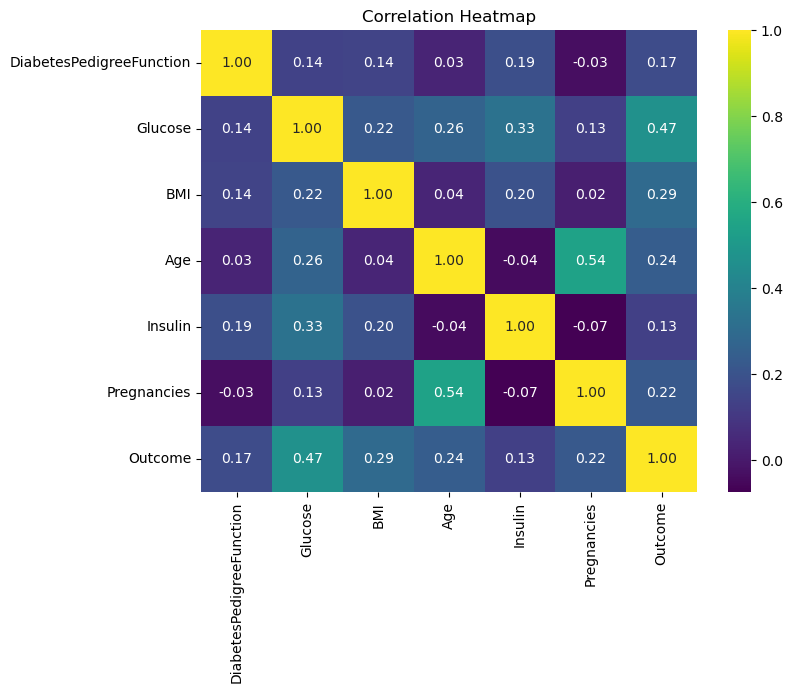

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

columns_for_heatmap = ['DiabetesPedigreeFunction', 'Glucose', 'BMI', 'Age', 'Insulin', 'Pregnancies', 'Outcome']  # Add other relevant features

heatmap_data = diabetes_dataset[columns_for_heatmap]

correlation_matrix = heatmap_data.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='viridis', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

## Preprocessing

In [18]:
diabetes_dataset.isna().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [19]:
# separating the data and labels
X = diabetes_dataset.drop(columns = 'Outcome', axis=1)
X

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63
764,2,122,70,27,0,36.8,0.340,27
765,5,121,72,23,112,26.2,0.245,30
766,1,126,60,0,0,30.1,0.349,47


In [20]:
y = diabetes_dataset['Outcome']
y

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

In [21]:
diabetes_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [22]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [23]:
scaler.fit(X)

StandardScaler()

In [24]:
X = scaler.transform(X)

In [25]:
y

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

### Data Splitting:
Split the data into training and testing sets.

In [26]:
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.1, random_state=44, stratify=y)

In [27]:
print("Training data shape: ", X_train.shape, y_train.shape)
print("Testing data shape: ", X_test.shape, y_test.shape)

Training data shape:  (691, 8) (691,)
Testing data shape:  (77, 8) (77,)


In [28]:
y_train.value_counts()

Outcome
0    450
1    241
Name: count, dtype: int64

Check the number of each class rows in `y_test`

In [29]:
y_test.value_counts()

Outcome
0    50
1    27
Name: count, dtype: int64

Divide the data set in a way to include 20% data in test dataset

In [30]:
from sklearn.model_selection import train_test_split

X = diabetes_dataset.drop(columns='Outcome', axis=1)
y = diabetes_dataset['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=44, stratify=y)

### Model Selection and Training:


SVM: Finds an optimal hyperplane to separate data into classes. Effective in high-dimensional spaces, handles non-linear data.


In [31]:
from sklearn.linear_model import LogisticRegression


log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train, y_train)



LogisticRegression(max_iter=1000)

## Evaluation
Evaluate the model on test data using metrics like accuracy, precision, recall, and F1-score.

## Accuracy Score
Accuracy: This measures the overall correctness of the model's prediction

In [32]:
from sklearn.metrics import accuracy_score

# accuracy score on the training data
y_train_predict = log_model.predict(X_train)
training_data_accuracy = accuracy_score(y_train_predict, y_train)
print('Accuracy score of the training data : ', training_data_accuracy)

Accuracy score of the training data :  0.7866449511400652


In [33]:
# accuracy score on the test data
y_test_predict = log_model.predict(X_test)
test_data_accuracy = accuracy_score(y_test_predict, y_test)
print('Accuracy score of the test data : ', test_data_accuracy)

Accuracy score of the test data :  0.7662337662337663


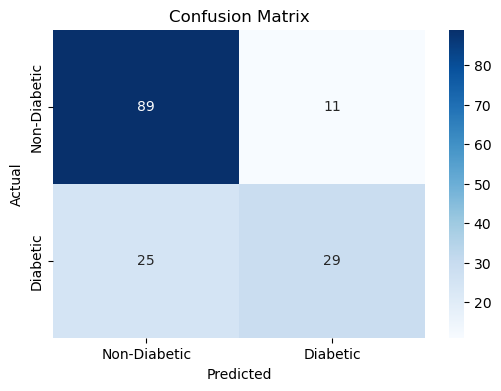

In [34]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_test_predict)

# Plot the confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Diabetic', 'Diabetic'], yticklabels=['Non-Diabetic', 'Diabetic'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Making a Predictive System

In [35]:
import numpy as np

input_data = (5,166,72,19,175,25.8,0.587,51)

input_data_as_numpy_array = np.asarray(input_data)

input_data_reshaped = input_data_as_numpy_array.reshape(1,-1)

std_data = scaler.transform(input_data_reshaped)
print(std_data)

prediction = log_model.predict(std_data)
print(prediction)

if (prediction[0] == 0):
  print('The person is not diabetic')
else:
  print('The person is diabetic')

[[ 0.3429808   1.41167241  0.14964075 -0.09637905  0.82661621 -0.78595734
   0.34768723  1.51108316]]
[0]
The person is not diabetic


c:\Users\PMYLS\anaconda3\Lib\site-packages\sklearn\base.py:464: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\PMYLS\anaconda3\Lib\site-packages\sklearn\base.py:464: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(




*   Precision: This focuses on the accuracy of positive predictions.
*   Recall (Sensitivity): This measures how well the model identifies actual positives.

*  F1-score: This metric balances precision and recall.





In [36]:
# Import necessary libraries
from sklearn.metrics import precision_score, recall_score, f1_score

# Precision, Recall, and F1-score
precision = precision_score(y_test, y_test_predict)
recall = recall_score(y_test, y_test_predict)
f1 = f1_score(y_test, y_test_predict)

print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1-score: {f1}")

Precision: 0.725
Recall: 0.5370370370370371
F1-score: 0.6170212765957447


## Decision Tree:

Builds a tree-like structure to make decisions based on a series of features.
Easy to interpret and visualize.
Can be prone to overfitting if not pruned properly.

In [37]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Create a Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions on the test set
dt_predictions = dt_model.predict(X_test)

# Evaluate the model
dt_accuracy = accuracy_score(y_test, dt_predictions)
dt_precision = precision_score(y_test, dt_predictions)
dt_recall = recall_score(y_test, dt_predictions)
dt_f1 = f1_score(y_test, dt_predictions)

print(f"Decision Tree Accuracy: {dt_accuracy:.4f}")
print(f"Decision Tree Precision: {dt_precision:.4f}")
print(f"Decision Tree Recall: {dt_recall:.4f}")
print(f"Decision Tree F1 Score: {dt_f1:.4f}")

Decision Tree Accuracy: 0.6818
Decision Tree Precision: 0.5455
Decision Tree Recall: 0.5556
Decision Tree F1 Score: 0.5505


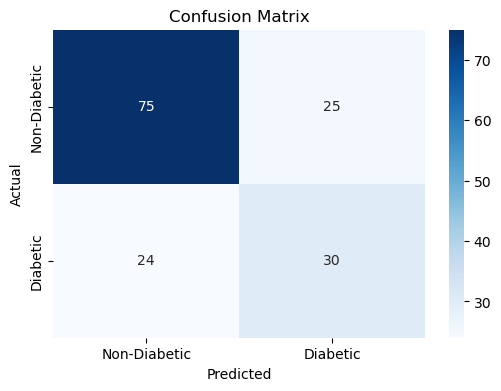

In [38]:
from sklearn.metrics import confusion_matrix

# Create a confusion matrix
cm = confusion_matrix(y_test, dt_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Diabetic', 'Diabetic'], yticklabels=['Non-Diabetic', 'Diabetic'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


## Random Forest:

An ensemble method that combines multiple decision trees to improve prediction accuracy and reduce overfitting.
Generally more robust and accurate than individual decision trees.

In [39]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score # Import necessary metrics

# Create a Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions on the test set
rf_predictions = rf_model.predict(X_test)

# Evaluate the model
rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions)
rf_recall = recall_score(y_test, rf_predictions)
rf_f1 = f1_score(y_test, rf_predictions)

print(f"Random Forest Accuracy: {rf_accuracy:.4f}")
print(f"Random Forest Precision: {rf_precision:.4f}")
print(f"Random Forest Recall: {rf_recall:.4f}")
print(f"Random Forest F1 Score: {rf_f1:.4f}")

Random Forest Accuracy: 0.7468
Random Forest Precision: 0.7027
Random Forest Recall: 0.4815
Random Forest F1 Score: 0.5714


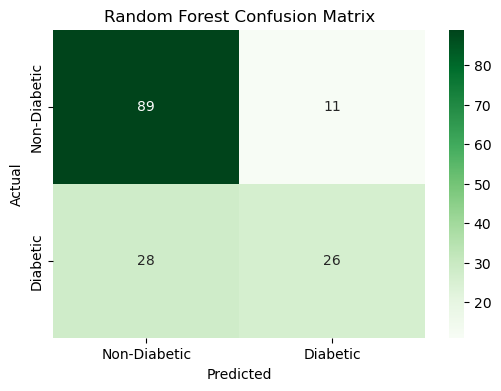

In [40]:
cm_rf = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', xticklabels=['Non-Diabetic', 'Diabetic'], yticklabels=['Non-Diabetic', 'Diabetic'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [41]:
import pandas as pd

# Generate predictions for Logistic Regression if not already stored
log_predictions = log_model.predict(X_test)

comparison_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, log_predictions),
        accuracy_score(y_test, dt_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    'Precision': [
        precision_score(y_test, log_predictions),
        precision_score(y_test, dt_predictions),
        precision_score(y_test, rf_predictions)
    ],
    'Recall': [
        recall_score(y_test, log_predictions),
        recall_score(y_test, dt_predictions),
        recall_score(y_test, rf_predictions)
    ],
    'F1 Score': [
        f1_score(y_test, log_predictions),
        f1_score(y_test, dt_predictions),
        f1_score(y_test, rf_predictions)
    ]
})

display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.7662,0.7250,0.5370,0.6170
1,Decision Tree,0.6818,0.5455,0.5556,0.5505
2,Random Forest,0.7468,0.7027,0.4815,0.5714


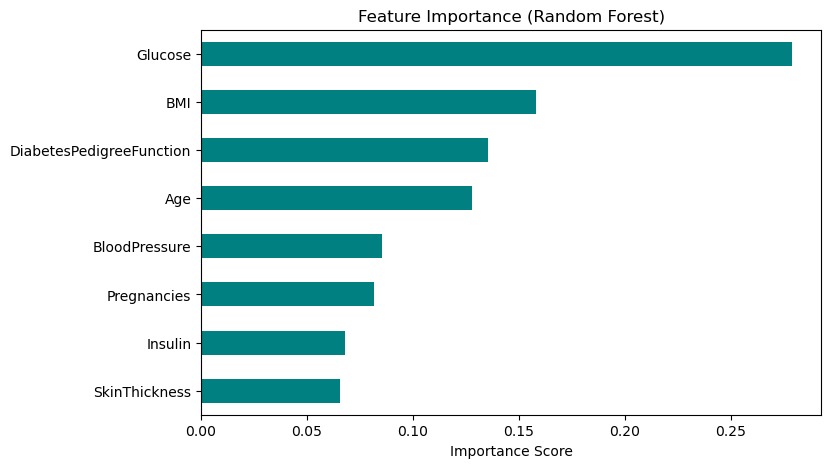

In [42]:
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importances.plot(kind='barh', color='teal')
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance Score")
plt.show()